In [93]:
import numpy as np
import scipy.integrate as integrate
from scipy.special import airy
import matplotlib.pyplot as plt


02.09.26
Trying to solve problem 1.3 and 1.4 numerically, from the notes given by Mats. 

1.3:
The heat equation
$$ u_t = u_{xx} $$
is the simplest example of a dissipative equation. 

a) What is the "dispersive relation" for the heat eq?

b) Show that $\frac{d}{dt} ||u||_{L^2(\mathbb{R})} < 0 $ for all nontrivial $u(t,\cdot) \in H^2(\mathbb{R})$,and that the corresponding devay is exponential for solutions in $C^2_{per}(\mathbb{R})$.

c) Find the solution for the heat eq. given initial data $u_0 \in C^\infty_0(\mathbb{R}) $. For general initial-data, what does this say about the regularity, support and long-time behaviour? Recalla Fourier transform of a Gaussian



In [94]:
# a) From the analytical solution, we have that the dispersion relation is pruly imaginary. 
# IOT show this here we use the test solution u(x,t) = exp(i(kx - wt)) 
# and solve the differential equation using FDM.
def spatial_double_derivative(u, dx):
    return (np.roll(u, -1) - 2 * u + np.roll(u, 1)) / dx**2 

def time_step(u, dt , dx):
    return u + dt * spatial_double_derivative(u, dx)

def f(x, t, k, w):
    return np.exp(1j * (k * x - w * t))

Numerical Im(omega): -9.0093
Continuum -k^2: -9.0000
Discrete symbol: -8.9933


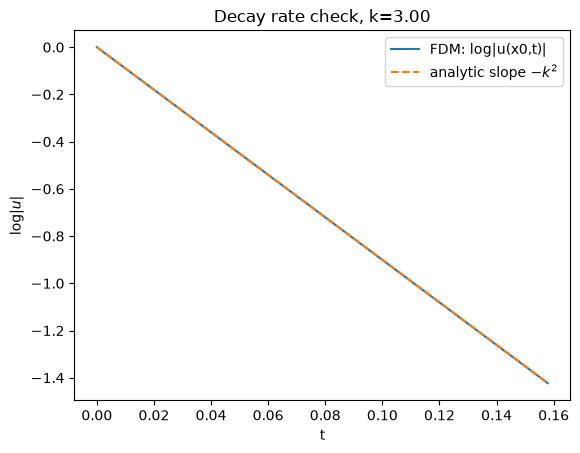

In [95]:
N = 200
L = np.pi * 2

#solving the differential equation using FDM
x = np.linspace(0, L, N , endpoint=False)
dx = x[1] - x[0]
dt = 0.4*dx**2
nsteps = 400
t_arr = np.arange(nsteps+1) * dt

m = 3
k = 2 * np.pi * m / L

u = f(x, 0, k, 0)

amp = np.zeros(nsteps +1)
amp[0] = np.abs(u[0])

for n in range(nsteps):
    u = time_step(u, dt, dx)
    amp[n + 1] = np.abs(u[0])


mask = amp > 1e-10
slope, _ = np.polyfit(t_arr[mask], np.log(amp[mask]), 1)

print(f"Numerical Im(omega): {slope:.4f}") # numerical slope of the log|u| decay
print(f"Continuum -k^2: {-k**2:.4f}") # analytic slope of the equation
print(f"Discrete symbol: {-4*np.sin(k*dx/2)**2/dx**2:.4f}") # analytic slope of the scheme


plt.plot(t_arr, np.log(amp), label='FDM: log|u(x0,t)|')
plt.plot(t_arr, np.log(amp[0]) - k**2 * t_arr, '--', label=r'analytic slope $-k^2$')
plt.xlabel('t'); plt.ylabel(r'$\log|u|$')
plt.legend(); plt.title(f'Decay rate check, k={k:.2f}')
plt.show()

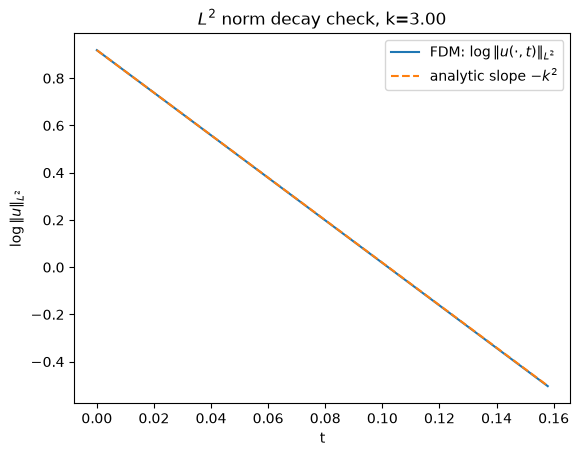

In [96]:
#b) to show that the dime derivative of u is negative we can simply compute the L^2 norm
# for each time step and use the forward time derivative to show that it is negative. 

U = np.zeros((nsteps + 1, N), dtype=complex)
U[0, :] = f(x, 0, k, 0)

l2_norm = np.zeros(nsteps + 1)
l2_norm[0] = np.linalg.norm(U[0])*np.sqrt(dx)

for n in range(nsteps):
    U[n + 1, :] = time_step(U[n, :], dt, dx)
    l2_norm[n + 1] = np.linalg.norm(U[n + 1]) * np.sqrt(dx)


mask = l2_norm > 1e-10
slope, _ = np.polyfit(t_arr[mask], np.log(l2_norm[mask]), 1)


plt.plot(t_arr, np.log(l2_norm), label=r'FDM: $\log\|u(\cdot,t)\|_{L^2}$')
plt.plot(t_arr, np.log(l2_norm[0]) - k**2 * t_arr, '--', label=r'analytic slope $-k^2$')
plt.xlabel('t'); plt.ylabel(r'$\log\|u\|_{L^2}$')
plt.legend(); plt.title(f'$L^2$ norm decay check, k={k:.2f}')
plt.show()

C:\Users\henri\AppData\Local\Temp\ipykernel_18868\3928861926.py:6: RuntimeWarning: divide by zero encountered in divide
  return np.exp(-1/(1-x**2)) * (np.abs(x) < 1)


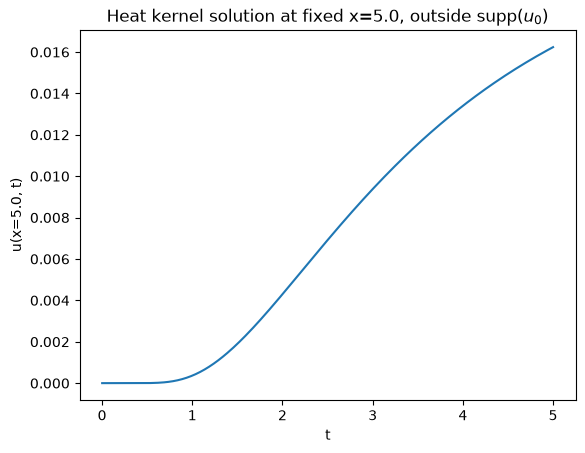

In [97]:
# c) Find the solution to the heat equation. 
# For this we choose u(x,0) as a bump function, and fix x_0 iot. use the
# Heat kernel and numerical integration to find the solution.

def bump_function(x):
    return np.exp(-1/(1-x**2)) * (np.abs(x) < 1)

def heat_kernel(x, t):
    return 1/np.sqrt(4*np.pi*t) * np.exp(-x**2/(4*t))



Ny = 4000
L = 10
y = np.linspace(-L, L, Ny, endpoint=False)
dy = y[1] - y[0]
u0 = bump_function(y)

def u_at(x0,t):
    G = heat_kernel(x0 - y, t)
    return np.trapezoid(G * u0, y)



x0 = 5.0   # note: this is OUTSIDE supp(u0) = (-2,2) !
t_arr = np.linspace(1e-3, 5, 300)
u_vals = np.array([u_at(x0, t) for t in t_arr])

plt.plot(t_arr, u_vals)
plt.xlabel('t')
plt.ylabel(f'u(x={x0}, t)')
plt.title(f'Heat kernel solution at fixed x={x0}, outside supp($u_0$)')
plt.show()

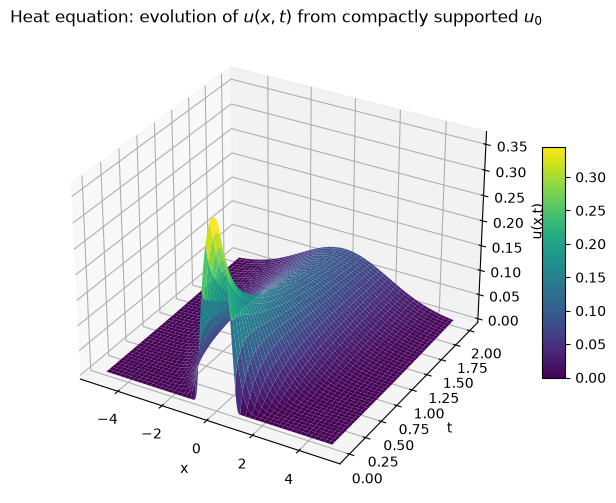

In [98]:
from mpl_toolkits.mplot3d import Axes3D

x_plot = np.linspace(-5, 5, 200)
t_plot = np.linspace(1e-3, 2, 200)
X,T = np.meshgrid(x_plot, t_plot)

U = np.zeros_like(X)
for i,t in enumerate(t_plot):
    G = heat_kernel(X[i,:] - y[:,None], t)
    U[i,:] = np.trapezoid(G * u0[:,None], y, axis=0)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, T, U, cmap='viridis', linewidth=0, antialiased=True)
ax.set_xlabel('x')
ax.set_ylabel('t')
ax.set_zlabel('u(x,t)')
ax.set_title('Heat equation: evolution of $u(x,t)$ from compactly supported $u_0$')
fig.colorbar(surf, shrink=0.5, aspect=10)
plt.show()

1.4:
The Airy equation is the linear ordinary differential equation
$$ y_{\xi \xi} - \xi y = 0 $$
Show that is $y(\xi)$ is a smooth solution of the Airy eq. then 
$$ u(t,x):= \frac{y(\xi)}{t^{1/3}}, \quad \xi:= \frac{x}{(3t)^{1/3}} $$
Solves the linear KdV equation for $t>0$. 

$$ u_t = u_{xxx} $$

In [99]:
# Let smake the Airy funciton

# def airy_function(x):
#   """Funker ikke grunnet numerisk integrasjon. Bruker scipy.special.airy i stedet."""
#     integrand = lambda t: np.cos((t**3)/3 + x*t)
#     val,err = integrate.quad(integrand,0, np.inf)
#     return val / np.pi


x_array = np.linspace(-10, 4, 400)
airy_values = np.array([airy(x) for x in x_array])



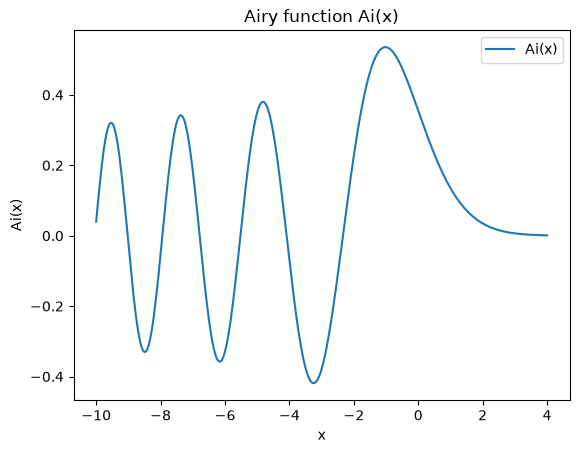

In [100]:
plt.plot(x_array, airy_values[:,0], label='Ai(x)')
# plt.plot(x_array, airy_values[:,2], label='Bi(x)')

plt.xlabel('x')
plt.ylabel('Ai(x)')
plt.title('Airy function Ai(x)')
plt.legend()
plt.show()

In [117]:
# we can then define the auxiliary funciton u(t,x) = Ai(\xi)*t^{-1/3} , \xi = x/t^{1/3}
# and show that it solves the linear KdV eq.

def u(t,x):
    xi = x / (3*t)**(1/3)
    return airy(xi)[0] * t**(-1/3)

def linear_kdv(u, t, x):
    """Check if u(t,x) satisfies the linear KdV equation: u_t + u_xxx = 0,
    Using finite difference approximations for the derivatives."""
    dt = 1e-3
    dx = 0.1
    
    # Compute u_t using finite difference
    u_t = (u(t + dt, x) - u(t-dt, x)) / (2*dt)
    
    # Compute u_xxx using finite difference
    u_xxx = (u(t,x+2*dx) - 3*u(t,x+dx) + 3*u(t,x-dx) - u(t,x-2*dx)) / (dx**3)
    
    return u_t, u_xxx

def semi_FDM_linear_KdV(u,t,x):
    """Check if u(t,x) satisfies the linear KdV equation: u_t + u_xxx = 0,
    Using the analytical expression for u_xxx and finite difference for u_t and u_x."""
    dt = 1e-3
    dx = 0.1
    
    # Compute u_t using finite difference
    u_t = (u(t + dt, x) - u(t-dt, x)) / (2*dt)
    
    # Compute u_xxx using the analytical expression for the third derivative of Ai(xi)
    xi = lambda y: y / (3*t)**(1/3)
    u_xxx = 1/3 * t**(-4/3) * (airy(xi(x+dx))[1] - 2*airy(xi(x))[1] + airy(xi(x-dx))[1])/dx**2 # using that airy()[1] is the derivative of Ai(x) and the 3 pt. stencil
    return u_t, u_xxx

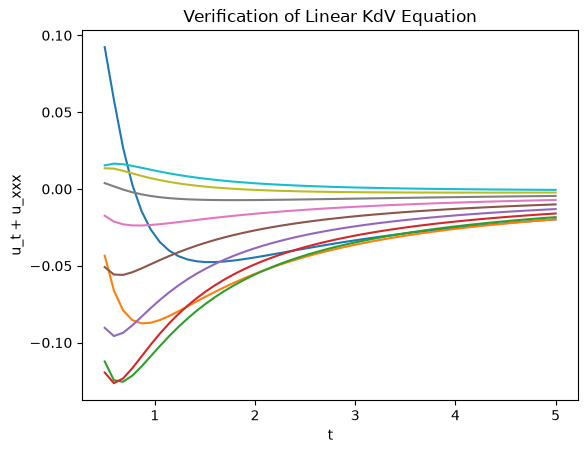

In [118]:
# Check if u(t,x) satisfies the linear KdV equation for a range of t and x values
t_values = np.linspace(0.5, 5, 50)
x_values = np.linspace(-2, 2, 10)

dtu, dxxxu = semi_FDM_linear_KdV(u, t_values[:, None], x_values[None, :])

plt.plot(t_values, dtu + dxxxu)
plt.xlabel('t')
plt.ylabel('u_t + u_xxx')
plt.title('Verification of Linear KdV Equation')
plt.show()



Uisng a closer approximation ot the analytical result gave a much better eror estimate-

In [119]:

ut0, ux0 = linear_kdv(u, 1.0, 0.0)
print("Using finite difference approximations:")
print(f"At t=1.0, x=0.0: u_t = {ut0:.6f}, u_xxx = {ux0:.6f}, u_t + u_xxx = {ut0 + ux0:.6f}")

ut0, ux0 = semi_FDM_linear_KdV(u, 1.0, 0.0)
print("Using semi-analytical approach:")
print(f"At t=1.0, x=0.0: u_t = {ut0:.6f}, u_xxx = {ux0:.6f}, u_t + u_xxx = {ut0 + ux0:.6f}")


Using finite difference approximations:
At t=1.0, x=0.0: u_t = -0.118343, u_xxx = 36.088307, u_t + u_xxx = 35.969964
Using semi-analytical approach:
At t=1.0, x=0.0: u_t = -0.118343, u_xxx = 0.056893, u_t + u_xxx = -0.061450


The method is numerically unstable. dx^3 can become really small, and thus blows up. Else i don't really understand the plot